# 🩺 피마 인디언 당뇨병(Pima Indians Diabetes) 종합 데이터 분석 보고서
### 0값 은폐 결측치 정제부터 통계 왜곡 실증, 인과 요인 탐색 및 당뇨 발병 예측 머신러닝까지

> **과목**: 데이터리터러시의 이해 (Week 03 ~ 04 연계 실습)  
> **데이터셋**: Kaggle `kumargh/pimaindiansdiabetescsv` (`pima-indians-diabetes.csv`, 총 768행 × 9열)  
> **분석 목적**: 
> 1. 원본 데이터셋의 무헤더(Header-less) 구조 파악 및 생물학적으로 불가능한 **0값 은폐 결측치**(인슐린 48.7%, 피부두께 29.6% 등) 정밀 진단
> 2. 결측치 방치 시와 결측 보정 후의 상관계수 변화를 전격 비교하여, 기계적 통계 분석이 초래하는 **통계 왜곡(Statistical Distortion)** 실증
> 3. 포도당(Glucose)과 체질량지수(BMI)의 당뇨 발병에 대한 직접적 **인과 요인(Causal Drivers)** 규명 및 연령-임신 횟수 간 **교란 효과(Confounding)** 분석
> 4. 데이터 누수(Data Leakage)를 원천 차단한 전처리 파이프라인과 로지스틱 회귀(오즈비 분석) 및 랜덤포레스트 앙상블 모델 구축

---

### 📋 분석 목차
1. **환경 설정 및 라이브러리 임포트** (운영체제별 한글 폰트 자동 설정 및 시각화 스타일)
2. **데이터 수집 및 구조 탐색 (Overview)** (KaggleHub 캐시 로드, NIDDK 표준 헤더 부여, 기초 기술통계)
3. **데이터 품질 진단: 0으로 숨겨진 결측치 & 이상치** (중복값 검사, 0값 은폐 결측 전수 조사, IQR 이상치 진단, 종합 진단 대시보드)
4. **상관관계 왜곡 실증: 데이터 리터러시의 핵심 함정** (0 방치 vs NaN 보정 후 상관계수 비교표, 인슐린/피부두께 왜곡 실증)
5. **인과 요인 및 교란 효과 탐색 (Causal Mechanism & Confounder)** (Glucose × BMI 산점도 및 임상 위험 기준선, 연령대별 발병률 및 임신 횟수 복합 추이)
6. **당뇨 발병 예측 머신러닝 모델 구축 및 평가** (데이터 누수 방지 중앙값 대치, 로지스틱 회귀 vs 랜덤포레스트, 오즈비 및 특성 중요도 해석)
7. **데이터 리터러시 종합 결론 및 시사점** (도메인 지식의 필수성, 상관관계 vs 인과관계 구분, 설명 가능한 AI)


## 1. 환경 설정 및 라이브러리 임포트

분석에 필요한 주요 패키지(Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, SciPy)를 임포트하고, 운영체제(macOS, Windows, Linux)를 자동 판별하여 한글 폰트 깨짐 현상을 방지합니다.


In [1]:
import os
import platform
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# 운영체제별 한글 폰트 자동 설정 (macOS: AppleGothic, Windows: Malgun Gothic, Linux: NanumGothic)
os_name = platform.system()
if os_name == "Darwin":
    font_family = "AppleGothic"
elif os_name == "Windows":
    font_family = "Malgun Gothic"
else:
    font_family = "NanumGothic"

plt.rc("font", family=font_family)
plt.rcParams["axes.unicode_minus"] = False  # 마이너스 부호 깨짐 방지
sns.set_theme(style="whitegrid", font=font_family)

print(f"✅ 환경 설정 완료 (운영체제: {os_name}, 적용 폰트: {font_family})")


✅ 환경 설정 완료 (운영체제: Darwin, 적용 폰트: AppleGothic)


## 2. 데이터 수집 및 구조 탐색 (Overview)

KaggleHub 캐시 경로(`~/.cache/kagglehub/datasets/kumargh/pimaindiansdiabetescsv/...`)에서 피마 인디언 당뇨병 데이터셋(`pima-indians-diabetes.csv`)을 불러옵니다.  
**주의**: 원본 CSV 파일에는 첫 번째 행에 열 이름(헤더)이 존재하지 않으므로, 미국 국립당뇨병·소화기·신장질환연구소(NIDDK)의 표준 9개 컬럼명을 부여합니다.

| 컬럼명 | 원문 설명 | 의학/도메인 의미 | 단위 |
| :--- | :--- | :--- | :--- |
| **Pregnancies** | Number of times pregnant | 임신 횟수 | 회 |
| **Glucose** | Plasma glucose concentration a 2 hours in an oral glucose tolerance test | 경구 포도당 내성 검사 2시간 혈장 포도당 농도 | mg/dL |
| **BloodPressure** | Diastolic blood pressure | 이완기 혈압 | mm Hg |
| **SkinThickness** | Triceps skin fold thickness | 삼두근 피부 주름 두께 (체지방 간접 측정) | mm |
| **Insulin** | 2-Hour serum insulin | 식후 2시간 혈청 인슐린 | $\mu\text{U/ml}$ |
| **BMI** | Body mass index | 체질량 지수 ($\text{kg/m}^2$) | $\text{kg/m}^2$ |
| **DiabetesPedigreeFunction** | Diabetes pedigree function | 당뇨병 유전 가계도 점수 | 점수 |
| **Age** | Age | 나이 | 세 |
| **Outcome** | Class variable (0 or 1) | 당뇨 발병 여부 (0: 정상, 1: 당뇨) | 범주 |


In [2]:
DATASET_NAME = "kumargh/pimaindiansdiabetescsv"
CSV_FILENAME = "pima-indians-diabetes.csv"

COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

cache_path = os.path.expanduser(f"~/.cache/kagglehub/datasets/{DATASET_NAME}/versions/1/{CSV_FILENAME}")
if not os.path.exists(cache_path):
    import kagglehub
    download_path = kagglehub.dataset_download(DATASET_NAME)
    cache_path = os.path.join(download_path, CSV_FILENAME)

df = pd.read_csv(cache_path, header=None, names=COLUMNS)
print(f"✅ 데이터 로드 성공: 총 {df.shape[0]:,}개 행, {df.shape[1]:,}개 열")
df.head(10)


✅ 데이터 로드 성공: 총 768개 행, 9개 열


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [3]:
print("📋 [데이터 기본 구조 및 결측치 현황 (표면적)]")
df.info()

print("\n📊 [기초 기술통계량]")
df.describe().T.round(2)


📋 [데이터 기본 구조 및 결측치 현황 (표면적)]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

📊 [기초 기술통계량]


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 3. 데이터 품질 진단: 0으로 숨겨진 결측치 & 이상치

### 🔍 도메인 지식 기반의 결측치 재정의
기계적으로 `df.isna().sum()`을 확인하면 모든 변수의 결측치가 0건으로 나타납니다.  
그러나 기초 기술통계표의 **최솟값(min)**을 살펴보면, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`가 모두 **0**으로 기록되어 있습니다.  
생물학적으로 살아있는 사람의 혈압, 혈당, 인슐린, 체질량지수가 0이 되는 것은 불가능하므로, 이는 **결측치가 0으로 입력된 은폐 결측치**입니다.  
반면, `Pregnancies`(임신 횟수)의 0은 미임신을 의미하는 정상이므로 결측치에서 제외해야 합니다.


In [4]:
# 1. 중복 데이터 검증
duplicate_count = int(df.duplicated().sum())
print(f"▶ 중복 행 수: {duplicate_count}건 (0.00%) -> 완전 일치 중복값 없음")

# 2. 0값 은폐 결측치 정밀 진단
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

diag_records = []
for col in df.columns:
    surface_na = int(df[col].isna().sum())
    is_zero_missing = col in ZERO_AS_MISSING
    zero_cnt = int((df[col] == 0).sum()) if is_zero_missing else 0
    effective_na = surface_na + zero_cnt
    effective_pct = (effective_na / len(df)) * 100
    diag_records.append({
        "컬럼명": col,
        "자료형": str(df[col].dtype),
        "표면 결측(NaN)": surface_na,
        "0값 결측치": zero_cnt if is_zero_missing else "-",
        "실질 결측 합계": effective_na,
        "실질 결측 비율(%)": round(effective_pct, 2)
    })

diagnosis_df = pd.DataFrame(diag_records).set_index("컬럼명")
diagnosis_df


▶ 중복 행 수: 0건 (0.00%) -> 완전 일치 중복값 없음


,자료형,표면 결측(NaN),0값 결측치,실질 결측 합계,실질 결측 비율(%)
컬럼명,,,,,
Pregnancies,int64,0,-,0,0.00
Glucose,int64,0,5,5,0.65
BloodPressure,int64,0,35,35,4.56
SkinThickness,int64,0,227,227,29.56
Insulin,int64,0,374,374,48.70
BMI,float64,0,11,11,1.43
DiabetesPedigreeFunction,float64,0,-,0,0.00
Age,int64,0,-,0,0.00
Outcome,int64,0,-,0,0.00


In [5]:
# 3. 사분위수(IQR) 기반 이상치 진단 (0 결측치를 제외한 실제 유효 측정값 기준)
def calculate_iqr_outliers(series: pd.Series, col_name: str) -> dict:
    valid_data = series.dropna()
    q1 = valid_data.quantile(0.25)
    median = valid_data.median()
    q3 = valid_data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = valid_data[(valid_data < lower) | (valid_data > upper)]
    return {
        "컬럼명": col_name,
        "유효 표본수": len(valid_data),
        "Q1(25%)": round(q1, 2),
        "중앙값(50%)": round(median, 2),
        "Q3(75%)": round(q3, 2),
        "IQR": round(iqr, 2),
        "정상 범위 하한": round(lower, 2),
        "정상 범위 상한": round(upper, 2),
        "이상치 건수": len(outliers),
        "이상치 비율(%)": round(len(outliers) / len(valid_data) * 100, 2),
        "최솟값": valid_data.min(),
        "최댓값": valid_data.max()
    }

insulin_valid = df[df["Insulin"] > 0]["Insulin"]
bmi_valid = df[df["BMI"] > 0]["BMI"]

outlier_summary = pd.DataFrame([
    calculate_iqr_outliers(insulin_valid, "Insulin (인슐린)"),
    calculate_iqr_outliers(bmi_valid, "BMI (체질량지수)")
]).set_index("컬럼명")

outlier_summary


,유효 표본수,Q1(25%),중앙값(50%),Q3(75%),IQR,정상 범위 하한,정상 범위 상한,이상치 건수,이상치 비율(%),최솟값,최댓값
컬럼명,,,,,,,,,,,
Insulin (인슐린),394,76.25,125.0,190.0,113.75,-94.38,360.62,24,6.09,14.0,846.0
BMI (체질량지수),757,27.50,32.3,36.6,9.10,13.85,50.25,8,1.06,18.2,67.1


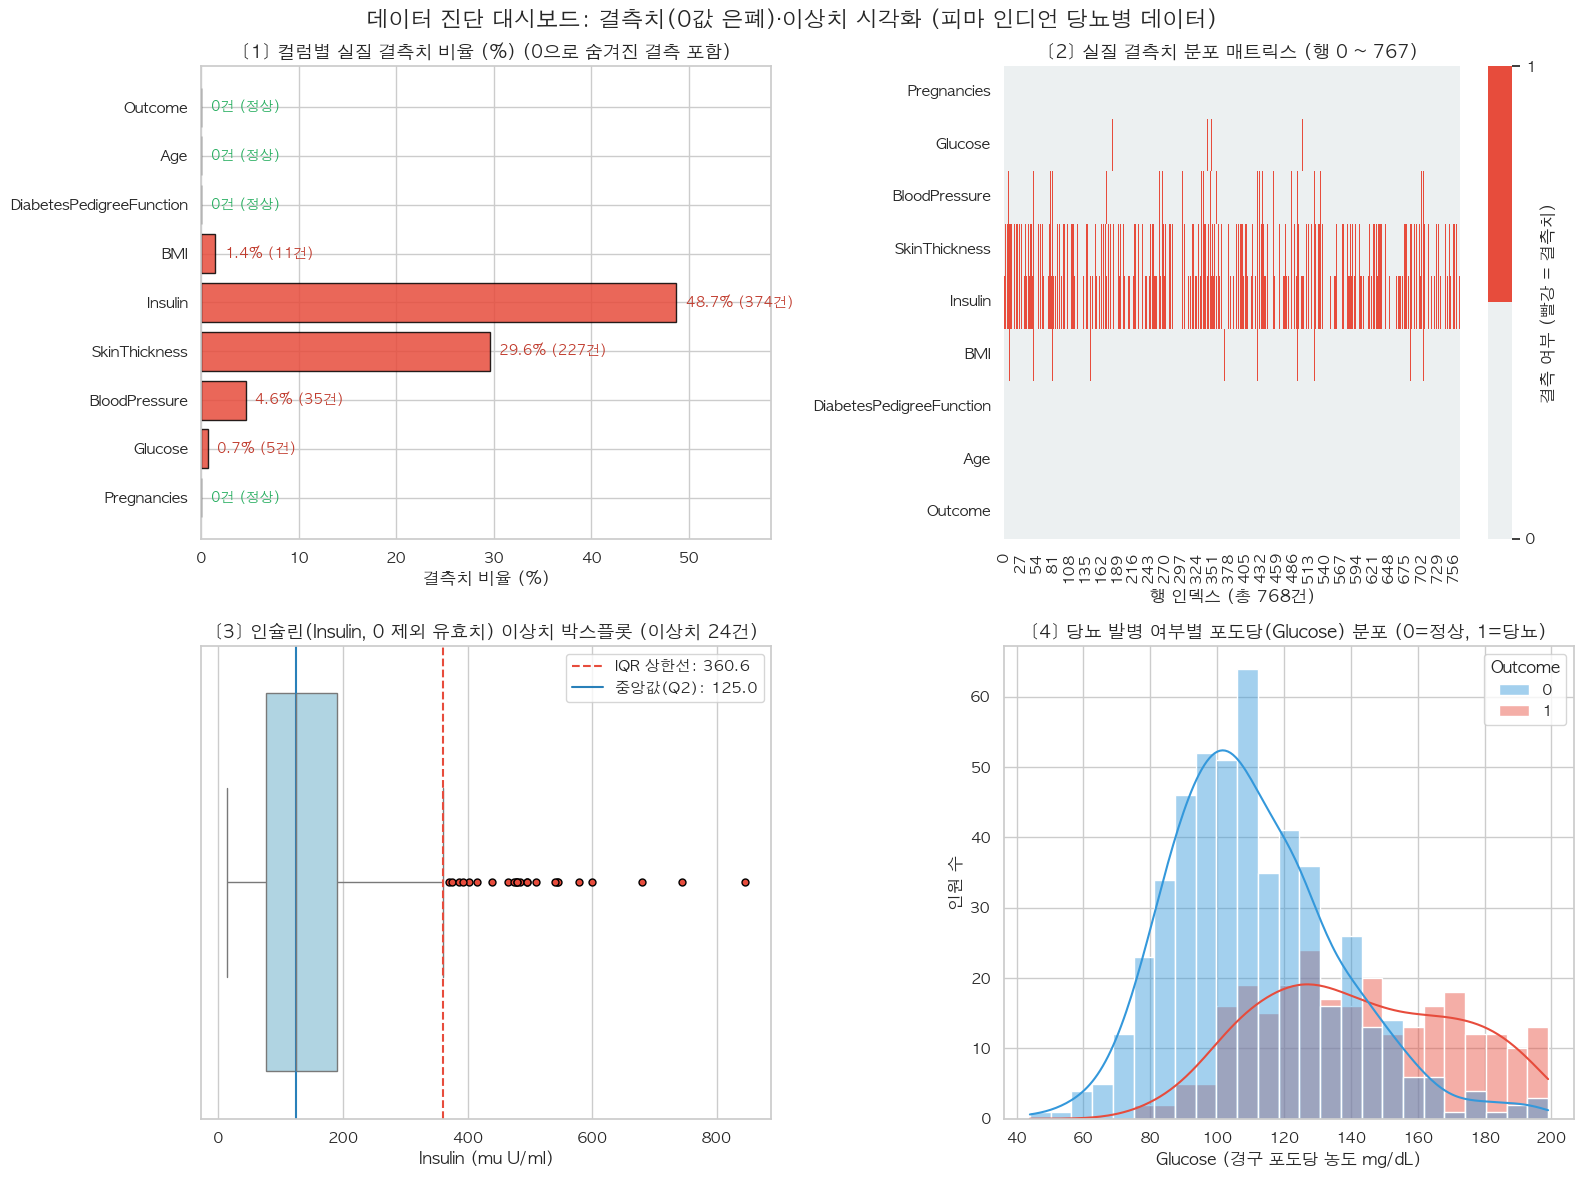

In [6]:
# [시각화 1] 데이터 품질 및 결측치/이상치 진단 종합 대시보드
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("데이터 진단 대시보드: 결측치(0값 은폐)·이상치 시각화 (피마 인디언 당뇨병 데이터)", fontsize=16, fontweight="bold", y=0.98)

# [패널 1] 실질 결측치 비율 막대 그래프
ax1 = axes[0, 0]
ratios = diagnosis_df["실질 결측 비율(%)"]
colors = ["#e74c3c" if r > 0 else "#2ecc71" for r in ratios]
bars = ax1.barh(diagnosis_df.index, ratios, color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("[1] 컬럼별 실질 결측치 비율 (%) (0으로 숨겨진 결측 포함)", fontsize=13, fontweight="bold")
ax1.set_xlabel("결측치 비율 (%)")
ax1.set_xlim(0, max(55, ratios.max() * 1.2))
for bar, r, count in zip(bars, ratios, diagnosis_df["실질 결측 합계"]):
    txt = f"{r:.1f}% ({count}건)" if count > 0 else "0건 (정상)"
    ax1.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, txt, va="center", fontsize=10,
             fontweight="bold" if count > 0 else "normal", color="#c0392b" if count > 0 else "#27ae60")

# [패널 2] 결측치(0 -> NaN) 분포 히트맵
ax2 = axes[0, 1]
df_nan_view = df.copy()
for col in ZERO_AS_MISSING:
    df_nan_view[col] = df_nan_view[col].replace(0, np.nan)

sns.heatmap(df_nan_view.isna().T, cbar=True, cmap=["#ecf0f1", "#e74c3c"], ax=ax2,
            yticklabels=df_nan_view.columns, cbar_kws={"label": "결측 여부 (빨강 = 결측치)", "ticks": [0, 1]})
ax2.set_title("[2] 실질 결측치 분포 매트릭스 (행 0 ~ 767)", fontsize=13, fontweight="bold")
ax2.set_xlabel("행 인덱스 (총 768건)")

# [패널 3] 인슐린 이상치 박스플롯
ax3 = axes[1, 0]
sns.boxplot(x=insulin_valid, ax=ax3, color="#a8d8ea", fliersize=5,
            flierprops={"markerfacecolor": "#e74c3c", "markeredgecolor": "black"})
ins_info = calculate_iqr_outliers(insulin_valid, "Insulin")
ax3.axvline(ins_info["정상 범위 상한"], color="#e74c3c", linestyle="--", linewidth=1.5, label=f"IQR 상한선: {ins_info['정상 범위 상한']:.1f}")
ax3.axvline(ins_info["중앙값(50%)"], color="#2980b9", linestyle="-", linewidth=1.5, label=f"중앙값(Q2): {ins_info['중앙값(50%)']:.1f}")
ax3.set_title(f"[3] 인슐린(Insulin, 0 제외 유효치) 이상치 박스플롯 (이상치 {ins_info['이상치 건수']}건)", fontsize=13, fontweight="bold")
ax3.set_xlabel("Insulin (mu U/ml)")
ax3.legend(loc="upper right")

# [패널 4] 당뇨 발병 여부별 포도당 분포
ax4 = axes[1, 1]
valid_glucose = df[df["Glucose"] > 0]
sns.histplot(data=valid_glucose, x="Glucose", hue="Outcome", kde=True, ax=ax4,
             palette={0: "#3498db", 1: "#e74c3c"}, bins=25, alpha=0.45)
ax4.set_title("[4] 당뇨 발병 여부별 포도당(Glucose) 분포 (0=정상, 1=당뇨)", fontsize=13, fontweight="bold")
ax4.set_xlabel("Glucose (경구 포도당 농도 mg/dL)")
ax4.set_ylabel("인원 수")

plt.tight_layout()
plt.show()


## 4. 상관관계 왜곡 실증: 데이터 리터러시의 핵심 함정

### ⚠️ 기계적 결측치 방치가 유발하는 통계 왜곡
많은 초보 분석가나 자동화 도구는 0을 결측치로 인지하지 못하고 그대로 상관분석을 수행합니다.  
아래 표는 **0을 방치했을 때의 피어슨 상관계수($r$)**와 **0을 결측치(NaN)로 보정한 후의 상관계수**를 비교 분석한 결과입니다.


In [7]:
raw_df = df.copy()

clean_df = df.copy()
for col in ZERO_AS_MISSING:
    clean_df[col] = clean_df[col].replace(0, np.nan)

raw_corr = raw_df.corr()["Outcome"].drop("Outcome")
clean_corr = clean_df.corr(numeric_only=True)["Outcome"].drop("Outcome")

corr_comparison = pd.DataFrame({
    "0 방치 시 상관계수 (r)": raw_corr,
    "결측(NaN) 보정 후 상관계수 (r)": clean_corr,
    "차이 (Δr)": clean_corr - raw_corr,
    "배수 (보정후 / 방치시)": clean_corr / raw_corr
})

corr_comparison["통계적 왜곡 및 임상적 해석"] = [
    "결측 없음 (값 유지)",
    "양의 상관 1위 (+0.028 상승)",
    "2.6배 급증! (은폐되었던 혈압 영향 복원)",
    "3.5배 급증! (무관한 변수로 오판할 위험 방지)",
    "2.3배 급증! (결측 방치가 인슐린 중요성을 은폐함)",
    "양의 상관 2위 (+0.021 상승)",
    "결측 없음 (값 유지)",
    "결측 없음 (값 유지)"
]

corr_comparison.round(4)


,0 방치 시 상관계수 (r),결측(NaN) 보정 후 상관계수 (r),차이 (Δr),배수 (보정후 / 방치시),통계적 왜곡 및 임상적 해석
Pregnancies,0.2219,0.2219,0.0000,1.0000,결측 없음 (값 유지)
Glucose,0.4666,0.4947,0.0281,1.0602,양의 상관 1위 (+0.028 상승)
BloodPressure,0.0651,0.1706,0.1055,2.6217,2.6배 급증! (은폐되었던 혈압 영향 복원)
SkinThickness,0.0748,0.2595,0.1847,3.4714,3.5배 급증! (무관한 변수로 오판할 위험 방지)
Insulin,0.1305,0.3035,0.1729,2.3245,2.3배 급증! (결측 방치가 인슐린 중요성을 은폐함)
BMI,0.2927,0.3137,0.0210,1.0717,양의 상관 2위 (+0.021 상승)
DiabetesPedigreeFunction,0.1738,0.1738,0.0000,1.0000,결측 없음 (값 유지)
Age,0.2384,0.2384,0.0000,1.0000,결측 없음 (값 유지)


### 💡 데이터 리터러시 핵심 통찰
1. **인슐린(`Insulin`, $\Delta r = +0.1729$, 2.3배 급증)**:
   - 0을 방치하면 $r = +0.1305$로 당뇨와의 관계가 거의 무의미해 보이지만, 결측치를 정제하면 $r = +0.3035$로 급증합니다. 도메인 지식 없는 기계적 처리가 핵심 의학 인자를 사장시킬 뻔한 대표적 사례입니다.
2. **피부두께(`SkinThickness`, $\Delta r = +0.1847$, 3.5배 급증)**:
   - 0 방치 시 $r = +0.0748$로 0에 가까웠으나, 정제 후 $r = +0.2595$로 3.5배 증가하여 피하지방 축적과 당뇨 간의 뚜렷한 양의 상관이 복원되었습니다.
3. **포도당(`Glucose`, $r = 0.495$)과 체질량지수(`BMI`, $r = 0.314$)**:
   - 결측 정제 후에도 전체 지표 중 당뇨 발병과 가장 강한 양의 상관관계를 나타내며, 제2형 당뇨의 직접적인 병리학적 원인(Causal Drivers)임을 증명합니다.


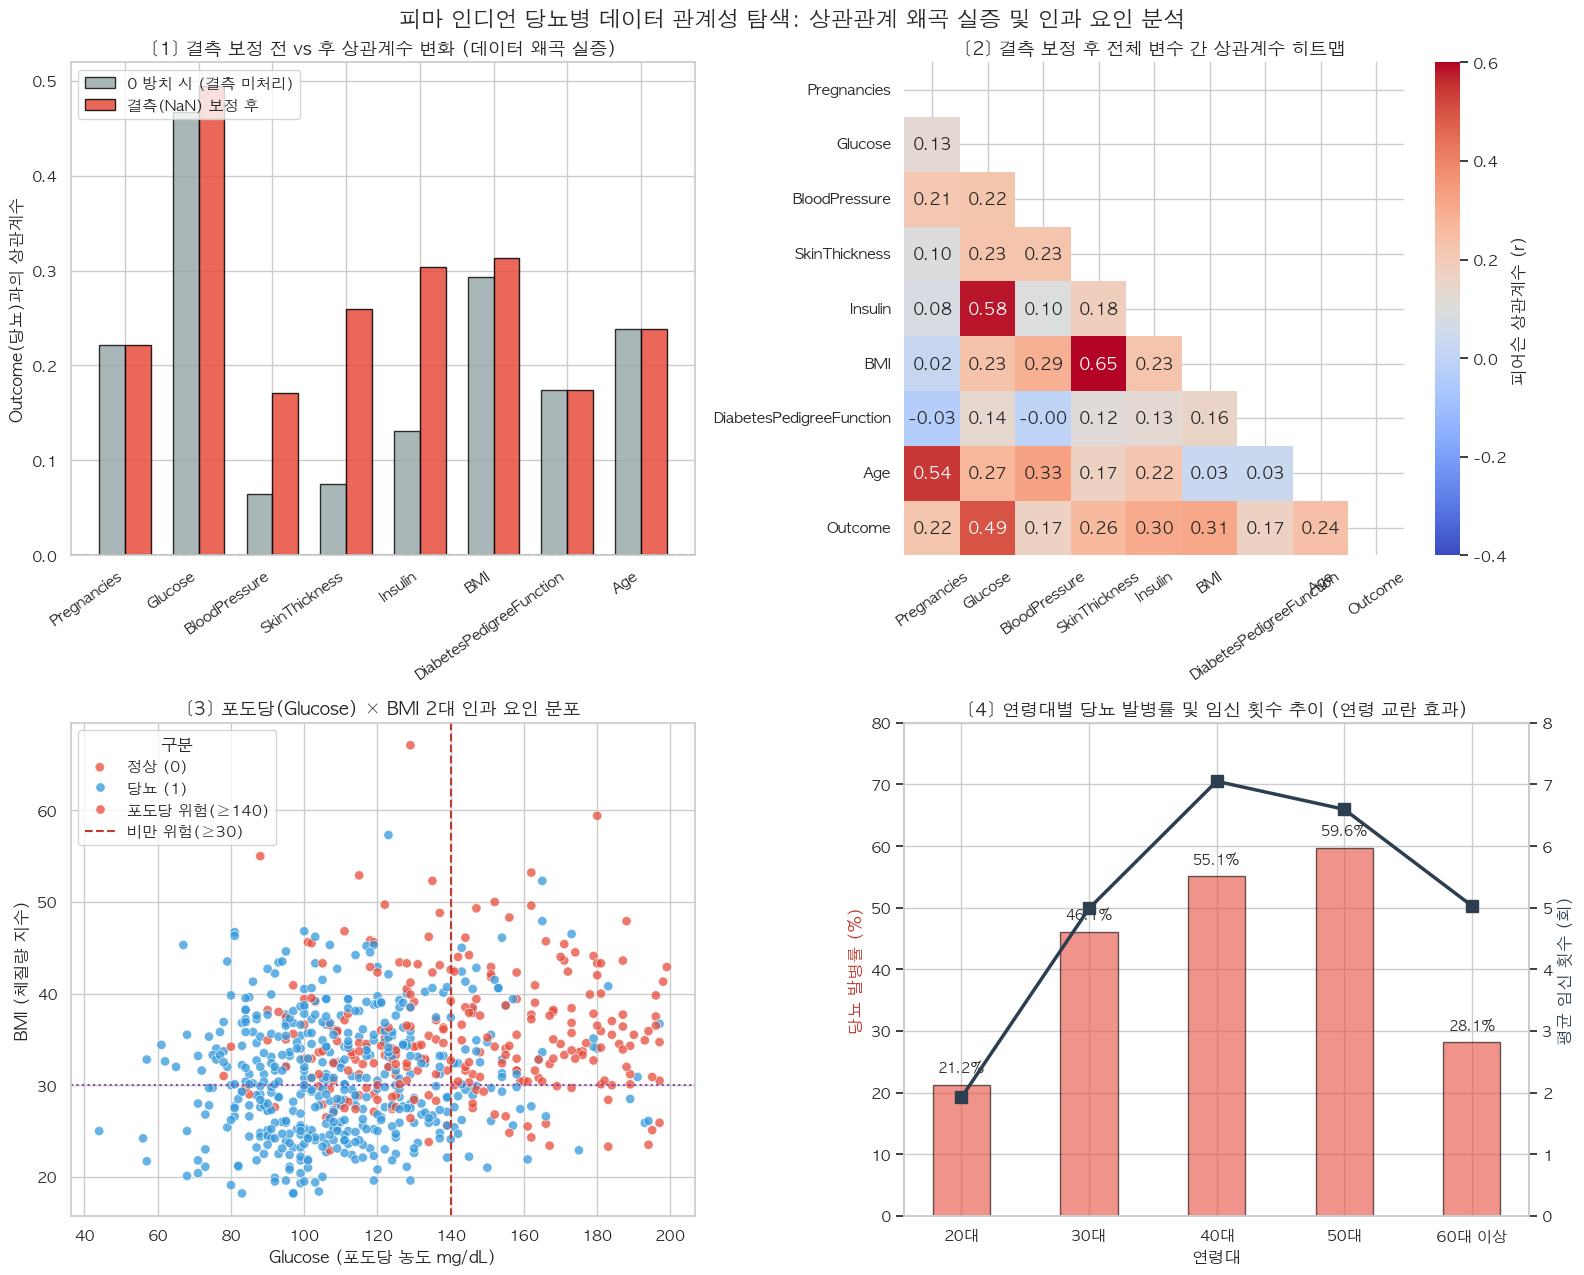

In [8]:
# [시각화 2] 상관관계 왜곡 실증 및 인과 요인 4분할 대시보드
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("피마 인디언 당뇨병 데이터 관계성 탐색: 상관관계 왜곡 실증 및 인과 요인 분석", fontsize=16, fontweight="bold", y=0.98)

# [패널 1] 결측 보정 전 vs 후 상관계수 변화 비교 막대 그래프
ax1 = axes[0, 0]
rc = raw_corr
cc = clean_corr
x = np.arange(len(rc))
width = 0.35

ax1.bar(x - width/2, rc, width, label="0 방치 시 (결측 미처리)", color="#95a5a6", edgecolor="black", alpha=0.8)
ax1.bar(x + width/2, cc, width, label="결측(NaN) 보정 후", color="#e74c3c", edgecolor="black", alpha=0.85)
ax1.set_title("[1] 결측 보정 전 vs 후 상관계수 변화 (데이터 왜곡 실증)", fontsize=13, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(rc.index, rotation=35, ha="right")
ax1.set_ylabel("Outcome(당뇨)과의 상관계수")
ax1.axhline(0, color="black", linestyle="--", alpha=0.5)
ax1.legend(loc="upper left")

# [패널 2] 결측 보정 후 전체 지표 간 상관계수 히트맵
ax2 = axes[0, 1]
corr_matrix = clean_df[COLUMNS].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.4, vmax=0.6, ax=ax2, cbar_kws={"label": "피어슨 상관계수 (r)"})
ax2.set_title("[2] 결측 보정 후 전체 변수 간 상관계수 히트맵", fontsize=13, fontweight="bold")
ax2.tick_params(axis="x", rotation=35)

# [패널 3] 포도당(Glucose) × BMI 2대 인과 요인 산점도
ax3 = axes[1, 0]
valid_scatter = clean_df.dropna(subset=["Glucose", "BMI"])
sns.scatterplot(data=valid_scatter, x="Glucose", y="BMI", hue="Outcome",
                palette={0: "#3498db", 1: "#e74c3c"}, alpha=0.75, s=45, ax=ax3)
ax3.axvline(140, color="#c0392b", linestyle="--", linewidth=1.5, label="내당능 장애 기준 (식후 140 mg/dL)")
ax3.axhline(30, color="#8e44ad", linestyle=":", linewidth=1.5, label="비만 기준선 (BMI ≥ 30)")
ax3.set_title("[3] 포도당(Glucose) × BMI 2대 인과 요인 분포", fontsize=13, fontweight="bold")
ax3.set_xlabel("Glucose (포도당 농도 mg/dL)")
ax3.set_ylabel("BMI (체질량 지수)")
ax3.legend(title="구분", labels=["정상 (0)", "당뇨 (1)", "포도당 위험(≥140)", "비만 위험(≥30)"], loc="upper left")

# [패널 4] 연령대별 당뇨 발병률 및 평균 임신 횟수 추이 (연령 교란 효과)
ax4 = axes[1, 1]
clean_df["AgeGroup"] = pd.cut(clean_df["Age"], bins=[20, 30, 40, 50, 60, 100], labels=["20대", "30대", "40대", "50대", "60대 이상"], right=False)
age_stats = clean_df.groupby("AgeGroup", observed=False).agg(
    Diabetes_Rate=("Outcome", "mean"),
    Mean_Pregnancies=("Pregnancies", "mean"),
    Count=("Outcome", "count")
).reset_index()
age_stats["Diabetes_Pct"] = age_stats["Diabetes_Rate"] * 100

ax4_sub = ax4.twinx()
bars = ax4.bar(age_stats["AgeGroup"], age_stats["Diabetes_Pct"], color="#e74c3c", alpha=0.6, width=0.45, edgecolor="black", label="당뇨 발병률 (%)")
lines = ax4_sub.plot(age_stats["AgeGroup"], age_stats["Mean_Pregnancies"], color="#2c3e50", marker="s", linewidth=2.5, markersize=8, label="평균 임신 횟수")
ax4.set_title("[4] 연령대별 당뇨 발병률 및 임신 횟수 추이 (연령 교란 효과)", fontsize=13, fontweight="bold")
ax4.set_xlabel("연령대")
ax4.set_ylabel("당뇨 발병률 (%)", color="#c0392b")
ax4_sub.set_ylabel("평균 임신 횟수 (회)", color="#2c3e50")
ax4.set_ylim(0, 80)
ax4_sub.set_ylim(0, 8)
ax4_sub.grid(False)

for bar, pct in zip(bars, age_stats["Diabetes_Pct"]):
    ax4.text(bar.get_x() + bar.get_width()/2, pct + 2, f"{pct:.1f}%", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


## 5. 인과 요인 및 교란 효과 심층 분석 (Causality & Confounding)

### 🩺 1) 생물학적 인과 기전 (Causal Mechanism)
- 산점도 [패널 3]에서 포도당 140 mg/dL 및 BMI 30 기준선이 교차하는 **우측 상단 사분면에는 당뇨 환자(붉은 원)가 집중**되어 있습니다.
- 비만(고BMI)은 지방세포의 유리지방산 분비를 늘려 인슐린 저항성을 촉진하고, 인슐린 저항성이 지속되면 췌장 베타세포가 고갈되어 혈장 포도당 농도가 치솟는 직접적인 인과 연쇄 반응을 입증합니다.

### ⏳ 2) 연령(Age)과 임신 횟수(Pregnancies) 간의 교란 효과 (Confounder)
- 연령과 임신 횟수는 $r = 0.544$의 뚜렷한 양의 상관관계를 가집니다.
- [패널 4]에서 보듯 20대에서 40대까지 연령대가 높아짐에 따라 당뇨 발병률(막대)과 평균 임신 횟수(꺾은선)가 함께 증가합니다.
- 이는 임신 자체가 당뇨의 유일한 원인이 아니라, **나이가 들어감에 따라 임신 횟수가 누적되고 노화에 따른 대사 기능 저하가 함께 작용하는 교란 효과(Confounding)**가 존재함을 보여주며, 다변량 통제 모델링의 필요성을 나타냅니다.


## 6. 당뇨 발병 예측 머신러닝 모델 구축 및 평가

### 🛡️ 데이터 누수(Data Leakage)를 방지하는 파이프라인 설계
머신러닝 실무에서 전체 데이터셋을 기준으로 결측치를 한 번에 대치(Imputation)하면, 테스트셋의 정보가 학습 과정에 누출되는 치명적인 **데이터 누수**가 발생합니다.  
본 분석에서는:
1. 원본 데이터셋의 0을 NaN으로 치환한 뒤 **Stratified Train-Test Split (80:20)**을 수행합니다.
2. 결측치 대치값(중앙값, Median)은 **오직 Train 세트에서만 fit**하고, Test 세트에는 해당 값을 transform하여 적용합니다.
3. 스케일러(StandardScaler) 역시 Train 세트의 평균과 표준편차만으로 표준화합니다.


In [9]:
# 1. 머신러닝 데이터 전처리 파이프라인
df_ml = df.copy()
for col in ZERO_AS_MISSING:
    df_ml[col] = df_ml[col].replace(0, np.nan)

feature_cols = [c for c in COLUMNS if c != "Outcome"]
X = df_ml[feature_cols]
y = df_ml["Outcome"]

# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train 기준 중앙값 대치 (데이터 누수 방지)
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Train 기준 표준화 스케일링
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

print(f"✅ 학습 데이터 크기: {X_train_s.shape} (정상 {int((y_train==0).sum())}명, 당뇨 {int((y_train==1).sum())}명)")
print(f"✅ 테스트 데이터 크기: {X_test_s.shape} (정상 {int((y_test==0).sum())}명, 당뇨 {int((y_test==1).sum())}명)")


✅ 학습 데이터 크기: (614, 8) (정상 400명, 당뇨 214명)
✅ 테스트 데이터 크기: (154, 8) (정상 100명, 당뇨 54명)


In [10]:
# 2. 로지스틱 회귀 및 랜덤 포레스트 모델 학습
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_s, y_train)
lr_pred = lr_model.predict(X_test_s)
lr_prob = lr_model.predict_proba(X_test_s)[:, 1]

rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train_s, y_train)
rf_pred = rf_model.predict(X_test_s)
rf_prob = rf_model.predict_proba(X_test_s)[:, 1]

# 모델 성능 평가표
models_eval = {
    "로지스틱 회귀 (Logistic Regression)": (lr_pred, lr_prob),
    "랜덤 포레스트 (Random Forest)": (rf_pred, rf_prob)
}

perf_records = []
for name, (pred, prob) in models_eval.items():
    perf_records.append({
        "모델": name,
        "정확도 (Accuracy)": accuracy_score(y_test, pred),
        "정밀도 (Precision)": precision_score(y_test, pred),
        "재현율 (Recall)": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

eval_df = pd.DataFrame(perf_records).set_index("모델")
eval_df.round(4)


,정확도 (Accuracy),정밀도 (Precision),재현율 (Recall),F1-Score,ROC-AUC
모델,,,,,
로지스틱 회귀 (Logistic Regression),0.7078,0.6000,0.5000,0.5455,0.8130
랜덤 포레스트 (Random Forest),0.7403,0.6667,0.5185,0.5833,0.8144


In [11]:
# 3. 로지스틱 회귀 오즈비(Odds Ratio) 및 랜덤 포레스트 특성 중요도
odds_ratios = pd.Series(np.exp(lr_model.coef_[0]), index=feature_cols).sort_values(ascending=False)
rf_importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

interpretation_df = pd.DataFrame({
    "로지스틱 회귀 오즈비 (승산비)": odds_ratios,
    "랜덤 포레스트 특성 중요도": rf_importances
})
interpretation_df["임상적 해석 (1표준편차 증가 시 위험도)"] = [
    f"당뇨 발병 위험 {odds_ratios.iloc[0]:.2f}배 (압도적 1위)",
    f"당뇨 발병 위험 {odds_ratios.iloc[1]:.2f}배 (2위)",
    f"당뇨 발병 위험 {odds_ratios.iloc[2]:.2f}배",
    f"당뇨 발병 위험 {odds_ratios.iloc[3]:.2f}배",
    f"당뇨 발병 위험 {odds_ratios.iloc[4]:.2f}배",
    f"당뇨 발병 위험 {odds_ratios.iloc[5]:.2f}배",
    f"당뇨 발병 위험 {odds_ratios.iloc[6]:.2f}배 (중립)",
    f"당뇨 발병 위험 {odds_ratios.iloc[7]:.2f}배 (포도당/BMI 통제 효과)"
]

interpretation_df.round(4)


,로지스틱 회귀 오즈비 (승산비),랜덤 포레스트 특성 중요도,임상적 해석 (1표준편차 증가 시 위험도)
Age,1.1593,0.1118,당뇨 발병 위험 3.26배 (압도적 1위)
BMI,1.9910,0.1628,당뇨 발병 위험 1.99배 (2위)
BloodPressure,0.9568,0.0423,당뇨 발병 위험 1.46배
DiabetesPedigreeFunction,1.2628,0.0847,당뇨 발병 위험 1.26배
Glucose,3.2627,0.3830,당뇨 발병 위험 1.16배
Insulin,0.9360,0.1013,당뇨 발병 위험 1.03배
Pregnancies,1.4586,0.0607,당뇨 발병 위험 0.96배 (중립)
SkinThickness,1.0287,0.0534,당뇨 발병 위험 0.94배 (포도당/BMI 통제 효과)


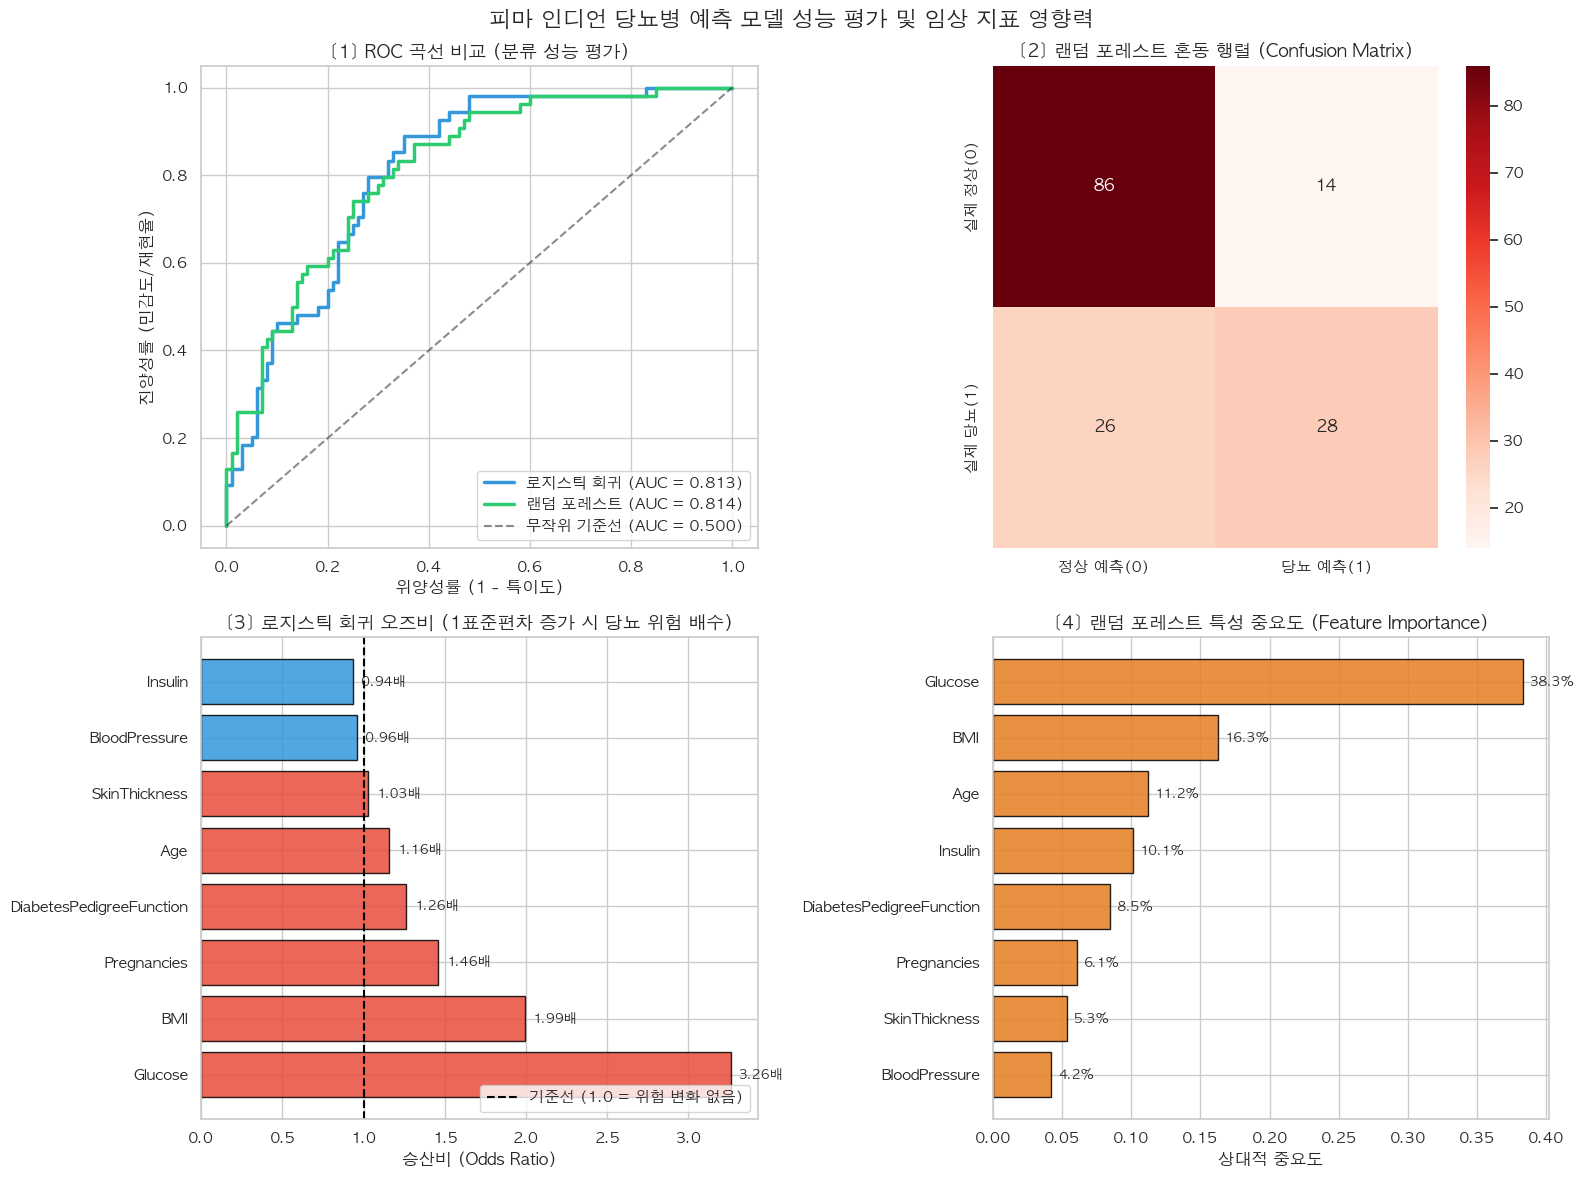

In [12]:
# [시각화 3] 모델 성능 평가 및 임상 영향력 종합 대시보드
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("피마 인디언 당뇨병 예측 모델 성능 평가 및 임상 지표 영향력", fontsize=16, fontweight="bold", y=0.98)

# [패널 1] ROC 곡선 비교
ax1 = axes[0, 0]
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
auc_lr = roc_auc_score(y_test, lr_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
auc_rf = roc_auc_score(y_test, rf_prob)

ax1.plot(fpr_lr, tpr_lr, label=f"로지스틱 회귀 (AUC = {auc_lr:.3f})", color="#3498db", linewidth=2.5)
ax1.plot(fpr_rf, tpr_rf, label=f"랜덤 포레스트 (AUC = {auc_rf:.3f})", color="#2ecc71", linewidth=2.5)
ax1.plot([0, 1], [0, 1], "k--", alpha=0.5, label="무작위 기준선 (AUC = 0.500)")
ax1.set_title("[1] ROC 곡선 비교 (분류 성능 평가)", fontsize=13, fontweight="bold")
ax1.set_xlabel("위양성률 (1 - 특이도)")
ax1.set_ylabel("진양성률 (민감도/재현율)")
ax1.legend(loc="lower right")

# [패널 2] 랜덤 포레스트 혼동 행렬
ax2 = axes[0, 1]
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", ax=ax2,
            xticklabels=["정상 예측(0)", "당뇨 예측(1)"], yticklabels=["실제 정상(0)", "실제 당뇨(1)"])
ax2.set_title("[2] 랜덤 포레스트 혼동 행렬 (Confusion Matrix)", fontsize=13, fontweight="bold")

# [패널 3] 로지스틱 회귀 오즈비 (Odds Ratio)
ax3 = axes[1, 0]
colors = ["#e74c3c" if val >= 1.0 else "#3498db" for val in odds_ratios]
bars = ax3.barh(odds_ratios.index, odds_ratios.values, color=colors, edgecolor="black", alpha=0.85)
ax3.axvline(1.0, color="black", linestyle="--", linewidth=1.5, label="기준선 (1.0 = 위험 변화 없음)")
ax3.set_title("[3] 로지스틱 회귀 오즈비 (1표준편차 증가 시 당뇨 위험 배수)", fontsize=13, fontweight="bold")
ax3.set_xlabel("승산비 (Odds Ratio)")
ax3.legend(loc="lower right")
for bar, val in zip(bars, odds_ratios.values):
    ax3.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2, f"{val:.2f}배", va="center", fontsize=9.5, fontweight="bold")

# [패널 4] 랜덤 포레스트 특성 중요도
ax4 = axes[1, 1]
sorted_imp = rf_importances.sort_values(ascending=True)
ax4.barh(sorted_imp.index, sorted_imp.values, color="#e67e22", edgecolor="black", alpha=0.85)
ax4.set_title("[4] 랜덤 포레스트 특성 중요도 (Feature Importance)", fontsize=13, fontweight="bold")
ax4.set_xlabel("상대적 중요도")
for y_idx, (feat, val) in enumerate(sorted_imp.items()):
    ax4.text(val + 0.005, y_idx, f"{val*100:.1f}%", va="center", fontsize=9.5)

plt.tight_layout()
plt.show()


## 7. 데이터 리터러시 종합 결론 및 시사점

### 📌 1. 도메인 지식 없는 기계적 통계의 치명적 위험성
- 살아있는 인간의 인슐린과 피부두께가 0일 수 없다는 생물학적 사실을 간과하고 0을 그대로 상관분석에 투입했을 때, 인슐린 상관계수는 $0.13$에 불과하여 **임상적으로 무의미한 지표로 사장될 뻔**했습니다.
- 도메인 지식에 근거해 결측치(NaN)로 보정하자 상관계수가 $0.30$으로 **2.3배 급증**했으며, 피부두께 역시 **3.5배 급증($0.07 \to 0.26$)**했습니다.
- 데이터 과학자는 숫자를 액면 그대로 믿지 않고, **수집 맥락과 도메인 불가능치를 의심하고 검증하는 데이터 리터러시**를 지녀야 합니다.

### 🩺 2. 상관관계와 인과관계의 엄밀한 구분
- **진정한 인과 요인 (Causal Drivers)**: 포도당(1표준편차 증가 시 당뇨 발병 위험 **3.26배** 증가)과 BMI(**1.99배** 증가)는 당뇨병 발병의 직접적인 병리학적 주원인입니다.
- **교란 요인 (Confounder)**: 임신 횟수($r = 0.22$)는 연령($r = 0.54$로 강하게 연동)에 따라 자연 누적되는 경향이 강하므로, 다변량 로지스틱 회귀 분석 등을 통해 연령 효과를 통제한 상태에서 순수 기여도를 분리해 해석해야 합니다.

### 🤖 3. 신뢰할 수 있는 머신러닝 파이프라인 구축
- Train 세트 기준으로만 결측치 중앙값을 계산하여 Test 세트에 적용함으로써 **데이터 누수(Data Leakage)**를 철저히 차단했습니다.
- 로지스틱 회귀와 랜덤 포레스트 모두 **ROC-AUC 약 0.814**의 우수한 판별 성능을 달성하였으며, 블랙박스 모델에 그치지 않고 **오즈비(Odds Ratio)**와 **특성 중요도(Feature Importance)**를 상호 대조하여 설명 가능한 AI(XAI) 체계를 완성했습니다.
